# Hide and seek — two minds, one world, an objective swapped one line at a time

**What this is.** Two `System`s — a prey and a predator, each with its own objective and its
own planner — coupled through their Markov blankets by `couple()` and run on a clock by the
composition driver. Nothing is shared between them: not beliefs, not objectives, not tables.
The only channel is the wires, which carry what each mind's action node realises and what
the world emits. Each mind's **term tree** can be read at any tick from its own model and the
observations it received, so the two objectives are readable side by side, and when one is
swapped the other mind's tree does not move.

| # | beat | the line that differs |
|---|---|---|
| 1 | by the book — both minds plan expected free energy | `obs_targets={"distance": …}`, `epistemic=True` |
| 2 | the prey stops fleeing and seeks occupancy | `terms=("occupancy:transition:me",)` on the prey alone |
| 3 | the predator stops hunting and gets curious | `epistemic=("*",)` on the predator alone |

The model is `examples/hide_and_seek.py`; the objectives are the ones vignette 1
(`objectives_a_la_carte.ipynb`) walked on a single mind. What is new here is that there are
two of them on one world, and that the world is a process in the same wiring.

One sentence on what this is *not*. A composite built by `merge()` — one System from several,
latents identified across the join — refuses components that carry an objective of their own,
because whose critic scores the joint policy is undecided (`amortization-debt-ledger.md`,
entry 4). Coupled minds never meet that question: each plans alone, on its own model, and
the other mind is a state it infers.

In [1]:
import dataclasses
import pathlib
import sys

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from hybrid_aif.objectives.base import term_sign, total

# The model lives beside this notebook; make it importable from the repo root as well.
_here = pathlib.Path("examples")
sys.path.insert(0, str(_here if _here.exists() else pathlib.Path.cwd()))
import hide_and_seek as hs  # noqa: E402

TEAL = "#00897B"  # the prey
AMBER = "#B8860B"  # the predator
GREY = "#ADADAD"
INK = "#3A3A3A"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.titlesize": 11.5,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.edgecolor": "#CCCCCC",
        "axes.labelcolor": INK,
        "text.color": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

N = 4  # the grid's side
TICKS = 40
SEED = 1  # one seed for every beat: the differences below are the objectives, not the draw

## The world, the minds, the wires

A `4 × 4` grid, five moves (stay and the four directions). A move into a wall stays; any other
move fails with probability `0.2` and stays too. The slip matters for the same reason it did
in vignette 1: a deterministic move has `H(s' | s, a) = 0`, and beat 2's occupancy leaf would
have nothing to say.

**The world** is a `System` with two positions and two action inputs, run forward as a process
(`System.as_env`). It emits both positions exactly and their Manhattan distance binned into
`{caught, adjacent, two away, three or more}`.

**Each mind** has two state factors, `me` and `other`, and three modalities wired from the
world. Its own moves are the world's table. The other mind is *modelled*: the prey models the
predator as chasing (a move that shortens the distance is likelier), the predator models the
prey as fleeing. Neither sees the other's objective or its tables; that is a modelling choice
each mind makes about a state it infers, exactly as it would about any other part of the world.

The objective, by the book: a preference over the `distance` channel — the predator's logits
favour `caught`, the prey's favour `three or more` — and the `epistemic` term on.

In [2]:
prey, predator = hs.mind("prey", n=N), hs.mind("predator", n=N)
wiring = hs.wiring(prey, predator, n=N)

print("participants:", list(wiring.minds), "+", list(wiring.processes))
print("wires (out-port -> in-port):")
for wire in wiring.wires:
    kind, size = wiring.types[wire.source]
    print(f"  {wire.source:<18} -> {wire.target:<22} {kind}, {size}")

participants: ['prey', 'predator'] + ['world']
wires (out-port -> in-port):
  prey.move          -> world.prey_move        level, 5
  predator.move      -> world.pred_move        level, 5
  world.prey_pos     -> prey.me_obs            level, 16
  world.pred_pos     -> prey.other_obs         level, 16
  world.distance     -> prey.distance          level, 4
  world.pred_pos     -> predator.me_obs        level, 16
  world.prey_pos     -> predator.other_obs     level, 16
  world.distance     -> predator.distance      level, 4


### Helpers

`game` runs one wiring for `TICKS` ticks under the `"simultaneous"` tick order — both minds
read the round's boundary, then the world steps once — and returns the record, one entry per
participant. A round is one tick of time under every order and the world steps once per
round, so the minds' one-move-per-tick tables hold under all three; `"sequential"` and
`"async"` would only let a later mind read an earlier one's act on a direct wire, and this
wiring has none. `term_table` prints a mind's term tree at tick 0, recomputed from the observations it
received over flat priors (every observation is exact, so the beliefs are one-hot at the
observed cells). `sweep` repeats a beat over ten seeds and reports how often the prey was
caught.

In [3]:
def swap(mind, **objective):
    # One mind, its objective re-declared; targets are dropped unless the objective keeps them.
    system, params = mind
    keep_targets = objective.pop("keep_targets", False)
    system = dataclasses.replace(system, **objective)
    params = params if keep_targets else dataclasses.replace(params, obs_targets={})
    return system, params


def game(prey, predator, seed=SEED, ticks=TICKS):
    return hs.play(prey, predator, ticks, jax.random.PRNGKey(seed), n=N)


FLAT = {f: hs.Categorical.from_probs(np.full(N * N, 1 / (N * N))) for f in ("me", "other")}


def term_table(name, mind, record, t=0):
    # The term tree of the policy this mind chose at tick t, leaf by leaf, from the
    # observations it received at t over flat priors (the declared start priors are one-hot,
    # and would pin the beliefs to the start cells whatever the observation said).
    system, params = mind
    obs = {m: v[t] for m, v in record[name].observations.items()}
    beliefs, _ = system.infer_states(params, obs, FLAT)
    q_pi, tree = system.infer_policies(params, beliefs)
    k = int(jnp.argmax(q_pi.probs))
    plan = " → ".join(hs.MOVES[a] for a in np.asarray(system.policies(params))[k][:, 0])
    g = total(tree)
    print(f"{name} at tick {t}:  plan {plan};  G = {float(g.midpoint[k]):+7.3f}")
    print(f"  {'term':<12}{'block':<16}{'sign':>5}{'leaf':>10}   warrant")
    for term, blocks in sorted(tree.items()):
        for block, leaf in sorted(blocks.items()):
            print(
                f"  {term:<12}{block:<16}{term_sign(term):>+5.0f}"
                f"{float(leaf.midpoint[k]):>10.3f}   {'exact' if leaf.derived else 'estimate'}"
            )
    print()


def show(record, title):
    # Distance over the game, and where each mind spent it.
    world = record["world"].observations
    distance = np.asarray(world["distance"])
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.0), constrained_layout=True,
                             gridspec_kw={"width_ratios": [2.4, 1, 1]})
    ax = axes[0]
    ax.step(np.arange(distance.size), distance, where="post", color=INK, lw=1.4)
    caught = np.flatnonzero(distance == 0)
    ax.scatter(caught, np.zeros_like(caught), color=AMBER, zorder=3, s=28, label="caught")
    ax.set_yticks(range(4), hs.DISTANCES)
    ax.set_xlabel("tick")
    ax.set_title(f"{title}: caught {caught.size} of {distance.size - 1} ticks")
    if caught.size:
        ax.legend(frameon=False, loc="upper right")
    for ax, key, name, colour in ((axes[1], "prey_pos", "prey", "Greens"),
                                  (axes[2], "pred_pos", "predator", "YlOrBr")):
        counts = np.bincount(np.asarray(world[key]), minlength=N * N).reshape(N, N)
        ax.imshow(counts, cmap=colour, vmin=0)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"where the {name} was")
    plt.show()


def sweep(prey, predator, seeds=10):
    caught = [hs.tally(game(prey, predator, seed=s))["caught"] for s in range(seeds)]
    return np.mean(caught), np.std(caught)


results = {}

## 1. By the book — two expected-free-energy agents, opposed

The predator wants `distance` at `caught`; the prey wants it at `three or more`. Both trees
carry a `utility` leaf on the distance channel and `infogain` leaves on the three observation
channels — the `me_obs` leaf is the slip, the `other_obs` leaf is what each mind does not know
about the other's next move under its model of it. The tables below are read at tick 0, both
minds in their corners.

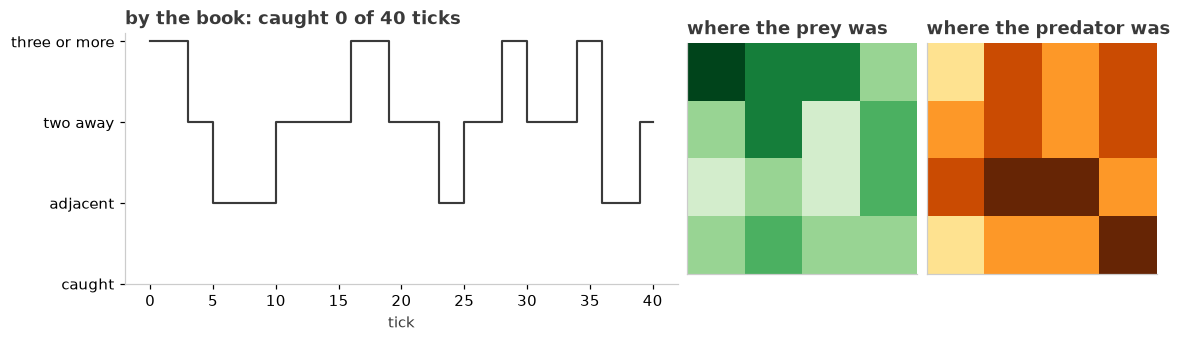

prey at tick 0:  plan south → east;  G =  -3.975
  term        block            sign      leaf   warrant
  infogain    distance           -1     0.659   exact
  infogain    me_obs             -1     1.501   exact
  infogain    other_obs          -1     2.821   exact
  utility     distance           -1    -1.006   exact

predator at tick 0:  plan north → west;  G = +12.293
  term        block            sign      leaf   warrant
  infogain    distance           -1     0.171   exact
  infogain    me_obs             -1     1.501   exact
  infogain    other_obs          -1     2.055   exact
  utility     distance           -1   -16.021   exact



In [4]:
record = game(prey, predator)
show(record, "by the book")
term_table("prey", prey, record)
term_table("predator", predator, record)
results["by the book"] = sweep(prey, predator)

Two trees, two signs on the same channel. The predator's `utility` leaf is large and negative
at any distance but contact, which is the whole of its drive; the prey's is small, because it
starts far away and far is what it wants. The `infogain` leaves are the same functional on
both sides and differ only through each mind's model of the other. Both start in corners at
the longest distance the grid has. Under the prey's model the predator is chasing, and from
its corner two moves shorten the distance, so the model spreads mass over three cells. Under
the predator's model the prey is fleeing, and from its corner no move lengthens the distance,
so the model falls back to uniform over the five moves' landing cells, three of which are the
corner itself. The fleer is the more predictable one, and the predator's `other_obs` leaf is
the smaller.

Read the wires again: the predator's tree is computed on the predator's model of the prey,
and the prey can change its mind without that tree moving. That is beat 2.

## 2. The prey seeks occupancy — one line, on one mind

`terms=("occupancy:transition:me",)` on the prey and nothing else: no preference over the
distance, no epistemic term. The predator is untouched, and so is its tree.

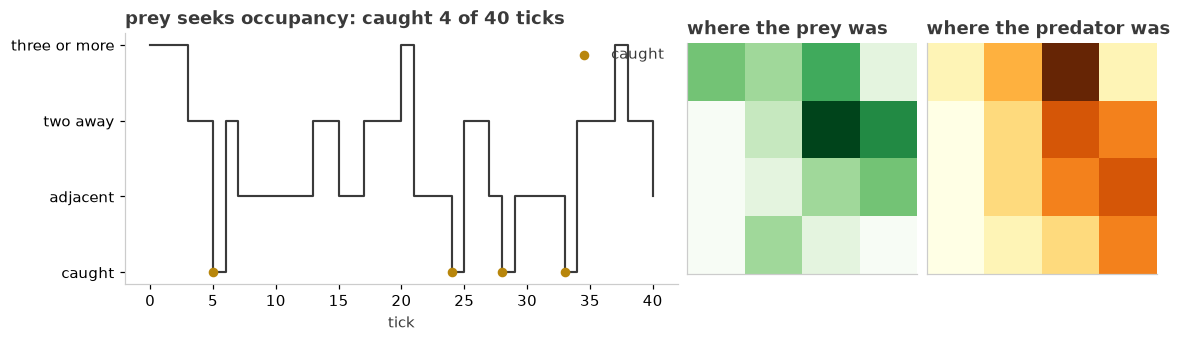

prey at tick 0:  plan south → south;  G =  -1.001
  term        block            sign      leaf   warrant
  occupancy   transition:me      -1     1.001   exact

predator at tick 0:  plan north → west;  G = +12.293
  term        block            sign      leaf   warrant
  infogain    distance           -1     0.171   exact
  infogain    me_obs             -1     1.501   exact
  infogain    other_obs          -1     2.055   exact
  utility     distance           -1   -16.021   exact



In [5]:
roamer = swap(prey, epistemic=False, terms=("occupancy:transition:me",))  # <- the line
record = game(roamer, predator)
show(record, "prey seeks occupancy")
term_table("prey", roamer, record)
term_table("predator", predator, record)
results["prey → occupancy"] = sweep(roamer, predator)

One leaf, and it is the prey's whole objective: the expected entropy of its own next
position, which is the slip on any real move and zero on a move into a wall. The prey keeps
moving and stops caring where the predator is, and the sweep says it is caught more often.
The predator's tree is beat 1's tree to the digit, because it is computed from the predator's
model and the predator's observations, and neither changed. Its model of the prey as a fleer
is now wrong, and nothing in its tree can tell it so — the wiring carries positions, not
objectives. A term tree is honest about its own arithmetic (every leaf here is `exact`) and
says nothing about whether its model is true.

## 3. The predator gets curious — one line, on the other mind

Back to the by-the-book prey. `epistemic=("*",)` on the predator and its preference dropped:
G is the information gain alone, over every observation channel.

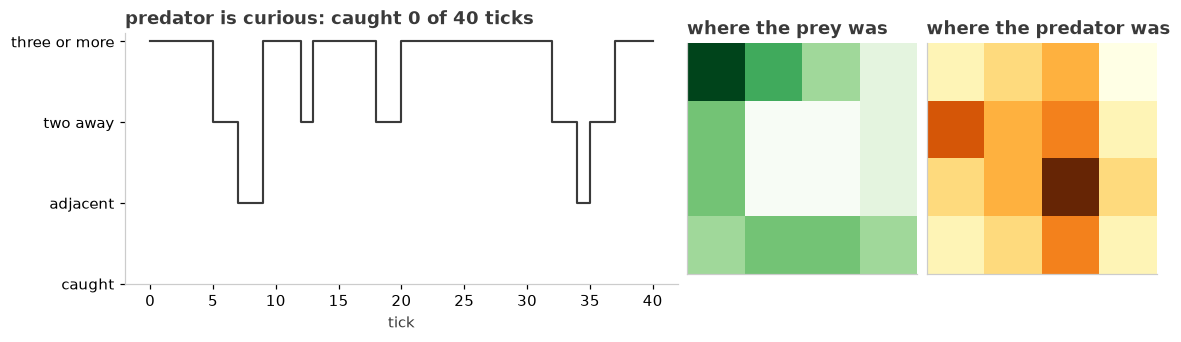

prey at tick 0:  plan south → east;  G =  -3.975
  term        block            sign      leaf   warrant
  infogain    distance           -1     0.659   exact
  infogain    me_obs             -1     1.501   exact
  infogain    other_obs          -1     2.821   exact
  utility     distance           -1    -1.006   exact

predator at tick 0:  plan north → west;  G =  -3.728
  term        block            sign      leaf   warrant
  infogain    distance           -1     0.171   exact
  infogain    me_obs             -1     1.501   exact
  infogain    other_obs          -1     2.055   exact



In [6]:
explorer = swap(predator, epistemic=("*",))  # <- the line
record = game(prey, explorer)
show(record, "predator is curious")
term_table("prey", prey, record)
term_table("predator", explorer, record)
results["predator → curiosity"] = sweep(prey, explorer)

The predator's `utility` leaf is gone and the three `infogain` leaves are what is left, and
the largest of them is `other_obs`: this predator values knowing where the prey will be, not
being there. An interest in the prey that no preference named is the kind of goal-directed
behaviour the occupancy paper argues is emergent, and here it falls out of one `infogain`
leaf. The predator goes wherever its predictions are least certain, and the sweep says the
prey is caught less often than under a predator that hunts. The prey's tree is beat 1's tree,
unchanged:
it still models the predator as a chaser and still plans to flee. Its model of the predator
is now wrong in the other direction, and again its tree does not know.

## The three beats side by side

Ten seeds each, forty ticks each; the same world, the same wiring, the same tick order.

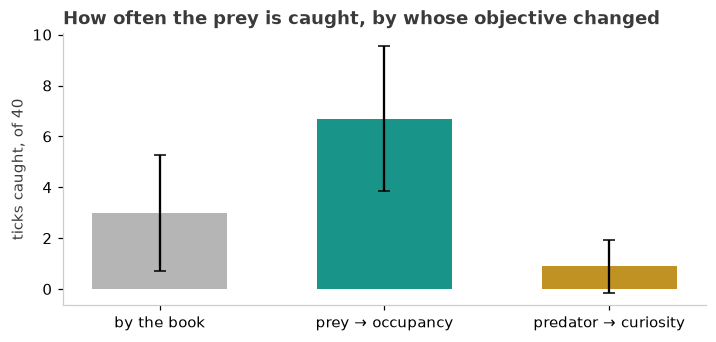

by the book            caught  3.0 ± 2.3 ticks of 40
prey → occupancy       caught  6.7 ± 2.9 ticks of 40
predator → curiosity   caught  0.9 ± 1.0 ticks of 40


In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.0), constrained_layout=True)
names = list(results)
means = [results[n][0] for n in names]
stds = [results[n][1] for n in names]
ax.bar(names, means, yerr=stds, color=[GREY, TEAL, AMBER], alpha=0.9, capsize=4, width=0.6)
ax.set_ylabel(f"ticks caught, of {TICKS}")
ax.set_title("How often the prey is caught, by whose objective changed")
plt.show()
for name in names:
    print(f"{name:<22} caught {results[name][0]:4.1f} ± {results[name][1]:.1f} ticks of {TICKS}")

**What the three beats share.** One world, one wiring, one driver, and two term trees that
are computed on nothing but each mind's own model and its own observations. Swapping an
objective is a one-line change to one `System`, and the other `System` is not rebuilt, not
re-planned, not told.

**What they do not share.** A joint critic. Each mind scores its own policies on its own
model of the other; there is no term here that reads both minds' objectives at once, and under
`couple()` there cannot be. That is the question `merge()` fences (ledger entry 4) rather than
answers, and it is a different design round. The tick order is the other dial this wiring
offers: `"simultaneous"` here; `"sequential"` and `"async"` are one argument to `run`, with
their semantics in `hybrid_aif.composition.driver`, and every order is one tick of time per
round.